In [1]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = np.array([100, 150, 200, 250, 300])
predicted = np.array([110, 140, 190, 260, 290])

print("MAE:", mean_absolute_error(actual, predicted))
print("MSE:", mean_squared_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
print("R2:", r2_score(actual, predicted))

MAE: 10.0
MSE: 100.0
RMSE: 10.0
R2: 0.98


In [2]:
import pandas as pd

actual = np.array([100, 150, 200, 250, 300])
predicted = np.array([110, 140, 190, 260, 290])

residuals = actual - predicted

residual_df = pd.DataFrame({
    "Actual": actual,
    "Predicted": predicted,
    "Residual": residuals
})

residual_df

,Actual,Predicted,Residual
0,100,110,-10
1,150,140,10
2,200,190,10
3,250,260,-10
4,300,290,10


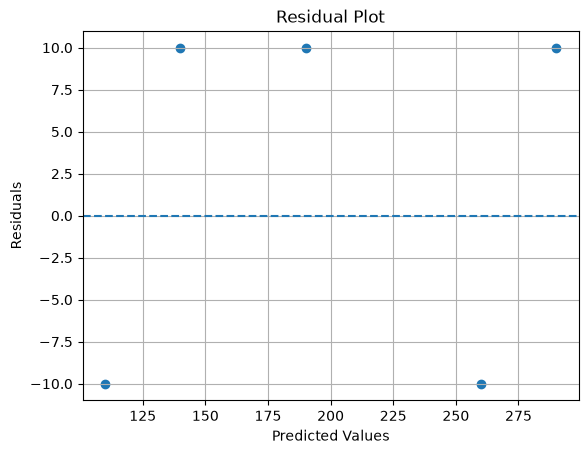

In [3]:
import matplotlib.pyplot as plt

plt.scatter(predicted, residuals)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

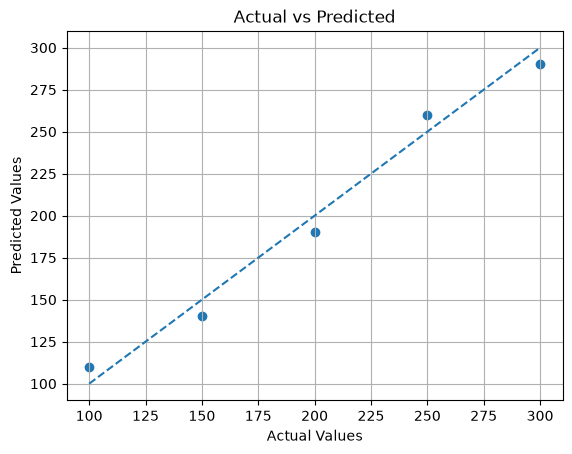

In [4]:
plt.scatter(actual, predicted)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.grid(True)
plt.show()

In [5]:
from sklearn.datasets import make_regression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

X, y = make_regression(
    n_samples=300,
    n_features=5,
    noise=20,
    random_state=42
)

model = LinearRegression()

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring="neg_mean_squared_error"
)

mse_scores = -scores

print("Fold MSE scores:", mse_scores)
print("Average MSE:", mse_scores.mean())
print("Average RMSE:", np.sqrt(mse_scores.mean()))

Fold MSE scores: [389.96462065 293.01272142 461.53860851 336.17157878 463.49567401]
Average MSE: 388.8366406729757
Average RMSE: 19.718941165107616


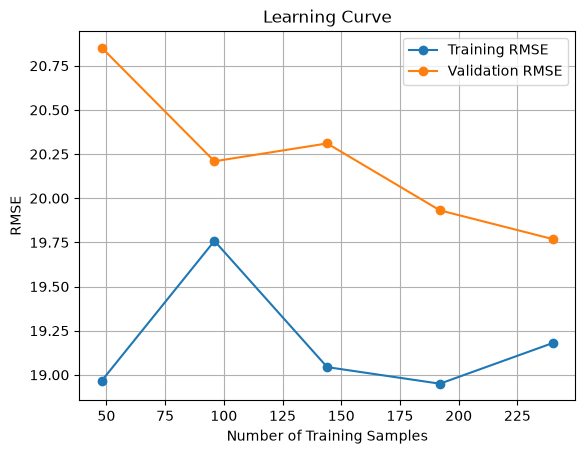

In [6]:
from sklearn.model_selection import learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X,
    y,
    cv=5,
    scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 5),
    random_state=42
)

train_rmse = np.sqrt(-train_scores.mean(axis=1))
val_rmse = np.sqrt(-val_scores.mean(axis=1))

plt.plot(train_sizes, train_rmse, marker="o", label="Training RMSE")
plt.plot(train_sizes, val_rmse, marker="o", label="Validation RMSE")

plt.xlabel("Number of Training Samples")
plt.ylabel("RMSE")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)
plt.show()

## Professional model evaluation workflow
For a real project, follow this approach:
1. Split data into training and test sets.
2. Use cross-validation on training data for model selection.
3. Tune hyperparameters using training data and cross-validation.
4. Select the final model.
5. Evaluate it once on the held-out test set.
6. Analyze residuals and document limitations.

For time-series data, use time-aware splitting rather than random splitting. For grouped data, consider group-aware splitting.